# E-Commerce Customer Segmentation & Prediction

Phase 1: Data Preparation

In [ ]:
# Step 1: Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Step 2: Load the Dataset
df = pd.read_csv('/content/data.csv', encoding='ISO-8859-1')
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (541909, 8)


In [91]:
import os

print("Dataset in /content:", os.path.exists('/content/data.csv'))
print("Dataset in project folder:",
      os.path.exists('/content/drive/MyDrive/ECommerce_Project_V1/data.csv'))

Dataset in /content: True
Dataset in project folder: True


In [ ]:
# Step 3: Understand the Dataset Structure

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [ ]:
# Step 4: Check Dataset Information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [ ]:

# Step 5: Check Missing Values
missing_values = df.isnull().sum()
print("Missing values in each column:")
print(missing_values)

Missing values in each column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [ ]:
# Step 6: Check Duplicate Records
duplicate_count = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 5268


In [ ]:

# Step 7: Remove Duplicate Records
df = df.drop_duplicates()
print("Duplicate records removed.")
print("Dataset shape after removing duplicates:", df.shape)

Duplicate records removed.
Dataset shape after removing duplicates: (536641, 8)


In [ ]:
# Step 8: Convert InvoiceDate to Datetime
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
print("InvoiceDate converted successfully.")
print("InvoiceDate data type:", df["InvoiceDate"].dtype)

InvoiceDate converted successfully.
InvoiceDate data type: datetime64[ns]


In [ ]:

# Step 9: Inspect Quantity and Unit Price
print("Quantity range:")
print("Minimum:", df["Quantity"].min())
print("Maximum:", df["Quantity"].max())
print("\nUnitPrice range:")
print("Minimum:", df["UnitPrice"].min())
print("Maximum:", df["UnitPrice"].max())

Quantity range:
Minimum: -80995
Maximum: 80995

UnitPrice range:
Minimum: -11062.06
Maximum: 38970.0


In [ ]:
# Step 10: Count Negative and Zero Values
print("Negative quantities:", (df["Quantity"] < 0).sum())
print("Zero quantities:", (df["Quantity"] == 0).sum())
print("Negative unit prices:", (df["UnitPrice"] < 0).sum())
print("Zero unit prices:", (df["UnitPrice"] == 0).sum())

Negative quantities: 10587
Zero quantities: 0
Negative unit prices: 2
Zero unit prices: 2510


In [ ]:
# Step 11: Remove Invalid Sales Records
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
print("Invalid sales records removed.")
print("Dataset shape after filtering:", df.shape)

Invalid sales records removed.
Dataset shape after filtering: (524878, 8)


In [ ]:
# Step 12: Remove Records with Missing Customer IDs
missing_customer_ids = df["CustomerID"].isnull().sum()
print("Records with missing CustomerID:", missing_customer_ids)
df = df.dropna(subset=["CustomerID"])
print("Dataset shape after removing missing CustomerIDs:", df.shape)

Records with missing CustomerID: 132186
Dataset shape after removing missing CustomerIDs: (392692, 8)


In [ ]:
# Step 13: Check Remaining Missing Values
print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


In [ ]:
# Step 14: Create the Revenue Column
df["Revenue"] = df["Quantity"] * df["UnitPrice"]
print("Revenue column created successfully.")
print(df[["Quantity", "UnitPrice", "Revenue"]].head())

Revenue column created successfully.
   Quantity  UnitPrice  Revenue
0         6       2.55    15.30
1         6       3.39    20.34
2         8       2.75    22.00
3         6       3.39    20.34
4         6       3.39    20.34


In [ ]:
# Step 15: Verify the Cleaned Dataset
print("Final dataset shape:", df.shape)
print("Total transactions:", len(df))
print("Total columns:", len(df.columns))
print("Unique customers:", df["CustomerID"].nunique())

Final dataset shape: (392692, 9)
Total transactions: 392692
Total columns: 9
Unique customers: 4338


In [ ]:
#Step 16: Statistical Summary of Numerical Columns
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID,Revenue
count,392692.000000,392692,392692.000000,392692.000000,392692.000000
mean,13.119702,2011-07-10 19:13:07.771892480,3.125914,15287.843865,22.631500
min,1.000000,2010-12-01 08:26:00,0.001000,12346.000000,0.001000
25%,2.000000,2011-04-07 11:12:00,1.250000,13955.000000,4.950000
50%,6.000000,2011-07-31 12:02:00,1.950000,15150.000000,12.450000
75%,12.000000,2011-10-20 12:53:00,3.750000,16791.000000,19.800000
max,80995.000000,2011-12-09 12:50:00,8142.750000,18287.000000,168469.600000
std,180.492832,NaN,22.241836,1713.539549,311.099224


In [ ]:
# Step 17: Inspect Extreme Quantity Values
df.nlargest(10, "Quantity")[
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "UnitPrice", "Revenue", "CustomerID"]
]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Revenue,CustomerID
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60,16446.0
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60,12346.0
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,1008.00,12901.0
206121,554868,22197,SMALL POPCORN HOLDER,4300,0.72,3096.00,13135.0
97432,544612,22053,EMPIRE DESIGN ROSETTE,3906,0.82,3202.92,18087.0
270885,560599,18007,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,0.06,191.16,14609.0
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,15749.0
160546,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,15749.0
433788,573995,16014,SMALL CHINESE STYLE SCISSOR,3000,0.32,960.00,16308.0
4945,536830,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,2880,0.18,518.40,16754.0


In [ ]:
# Step 18: Count Transactions with Extremely High Quantities
high_quantity_count = (df["Quantity"] > 1000).sum()
print("Transactions with Quantity > 1000:", high_quantity_count)
print("Percentage of dataset:", round(high_quantity_count / len(df) * 100, 3), "%")

Transactions with Quantity > 1000: 104
Percentage of dataset: 0.026 %


In [ ]:
# Step 19: Filter Extreme Quantity Values
df = df[df["Quantity"] <= 1000].copy()
print("Extreme quantity records filtered.")
print("Dataset shape:", df.shape)
print("Maximum quantity:", df["Quantity"].max())

Extreme quantity records filtered.
Dataset shape: (392588, 9)
Maximum quantity: 1000


In [ ]:
# Step 20: Inspect Highest Unit Prices
df.nlargest(10, "UnitPrice")[
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "UnitPrice", "Revenue", "CustomerID"]
]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Revenue,CustomerID
173382,551697,POST,POSTAGE,1,8142.75,8142.75,16029.0
422351,573077,M,Manual,1,4161.06,4161.06,12536.0
422376,573080,M,Manual,1,4161.06,4161.06,12536.0
406406,571751,M,Manual,1,3949.32,3949.32,12744.0
374542,569382,M,Manual,1,3155.95,3155.95,15502.0
297438,562946,M,Manual,1,2500.00,2500.00,15581.0
144826,548813,M,Manual,1,2382.92,2382.92,12744.0
406407,571751,M,Manual,1,2118.74,2118.74,12744.0
144829,548820,M,Manual,1,2053.07,2053.07,12744.0
343000,566927,M,Manual,1,2033.10,2033.10,17846.0


In [ ]:
# Step 21: Remove Non-Product Transactions
df_clean_backup = df.copy()
non_product_codes = ["POST", "M", "D", "C2", "BANK CHARGES"]
df = df[~df["StockCode"].isin(non_product_codes)].copy()
print("Non-product transaction records removed.")
print("Dataset shape:", df.shape)
print("Remaining non-product codes:",
      df[df["StockCode"].isin(non_product_codes)]["StockCode"].unique())

Non-product transaction records removed.
Dataset shape: (391067, 9)
Remaining non-product codes: []


In [ ]:
# Step 22: Verify the Cleaned Dataset
print("Dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Total missing values:", df.isnull().sum().sum())
print("Unique customers:", df["CustomerID"].nunique())
print("Unique invoices:", df["InvoiceNo"].nunique())
print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

Dataset shape: (391067, 9)
Duplicate rows: 0
Total missing values: 0
Unique customers: 4327
Unique invoices: 18369
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


# Phase 2 — Exploratory Data Analysis (EDA)

In [ ]:
# Step 23: Calculate Overall Business Metrics
total_revenue = df["Revenue"].sum()
total_units_sold = df["Quantity"].sum()
average_line_revenue = df["Revenue"].mean()
total_invoices = df["InvoiceNo"].nunique()
average_order_value = df.groupby("InvoiceNo")["Revenue"].sum().mean()
unique_products = df["StockCode"].nunique()
print("Total Revenue:", round(total_revenue, 2))
print("Total Units Sold:", total_units_sold)
print("Average Revenue per Transaction Line:", round(average_line_revenue, 2))
print("Total Unique Invoices:", total_invoices)
print("Average Order Value:", round(average_order_value, 2))
print("Unique Product Codes:", unique_products)

Total Revenue: 8349071.49
Total Units Sold: 4819990
Average Revenue per Transaction Line: 21.35
Total Unique Invoices: 18369
Average Order Value: 454.52
Unique Product Codes: 3659


In [ ]:
# Step 24: Analyze Revenue by Country
country_revenue = (
    df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)
print("Top 10 Countries by Revenue:")
print(country_revenue.head(10).round(2))

Top 10 Countries by Revenue:
Country
United Kingdom    6872931.73
Netherlands        273966.78
EIRE               256782.72
Germany            205381.15
France             183801.94
Australia          137470.21
Spain               55706.56
Switzerland         52441.95
Belgium             36927.34
Sweden              36828.83
Name: Revenue, dtype: float64


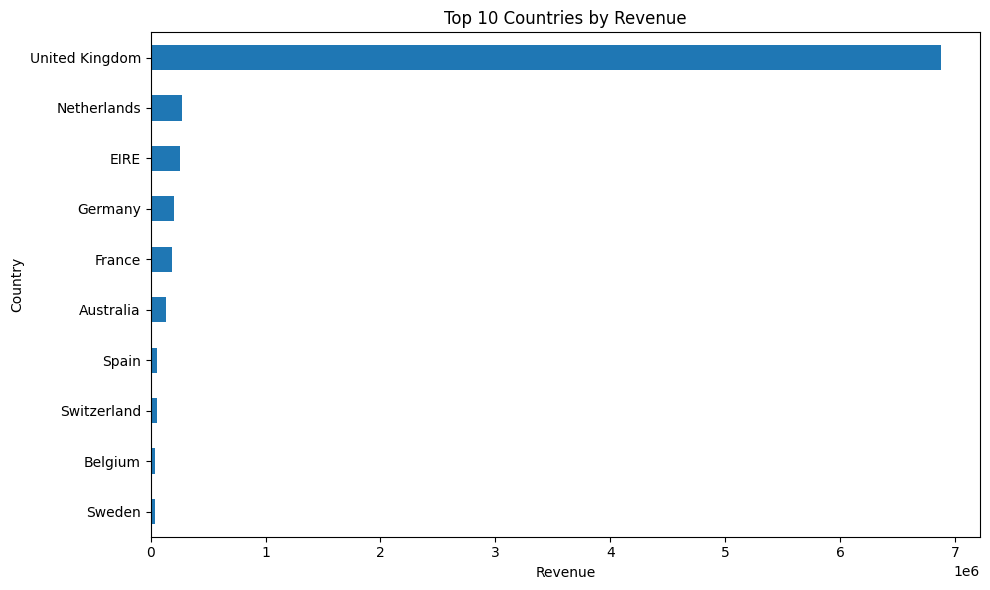

In [ ]:
# Step 25: Visualize Top 10 Countries by Revenue
top_10_countries = country_revenue.head(10).sort_values()
plt.figure(figsize=(10, 6))
top_10_countries.plot(kind="barh")
plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [ ]:
# Step 26: Identify Top 10 Products by Revenue
product_revenue = (
    df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)
print("Top 10 Products by Revenue:")
print(product_revenue.head(10).round(2))

Top 10 Products by Revenue:
Description
REGENCY CAKESTAND 3 TIER              142264.75
WHITE HANGING HEART T-LIGHT HOLDER     87566.20
JUMBO BAG RED RETROSPOT                83060.54
PARTY BUNTING                          68785.23
ASSORTED COLOUR BIRD ORNAMENT          50497.03
CHILLI LIGHTS                          46265.11
RABBIT NIGHT LIGHT                     40030.04
PAPER CHAIN KIT 50'S CHRISTMAS         39983.13
PICNIC BASKET WICKER 60 PIECES         39619.50
BLACK RECORD COVER FRAME               39045.80
Name: Revenue, dtype: float64


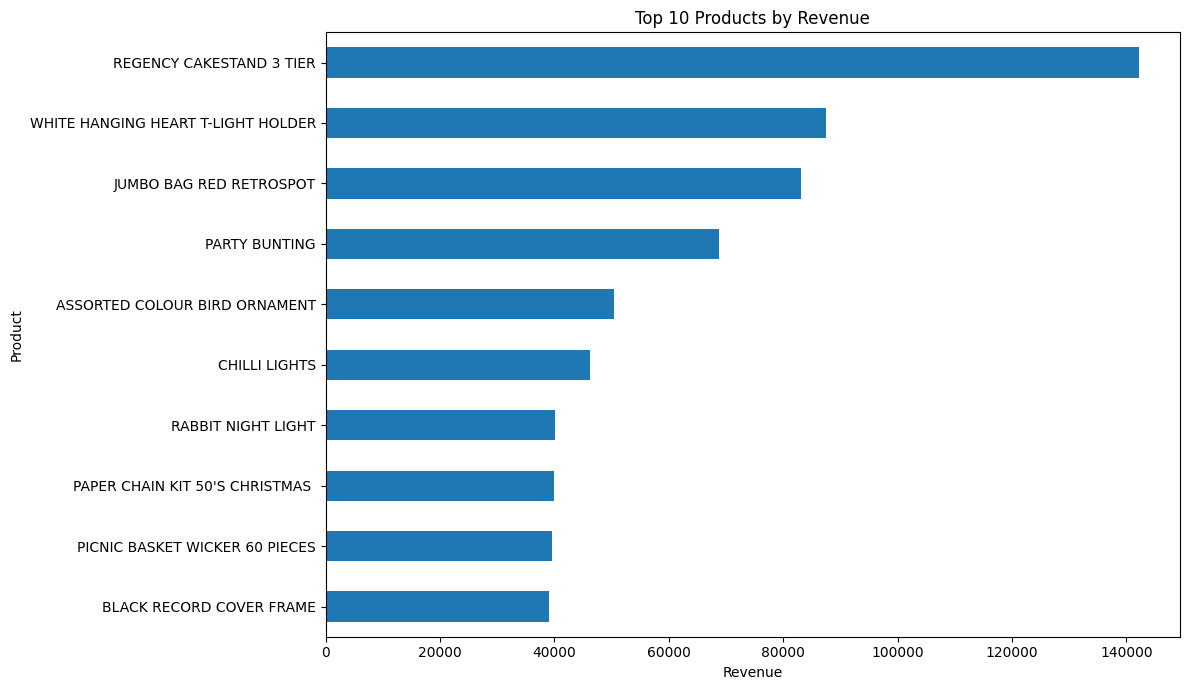

In [ ]:
# Step 27: Visualize Top 10 Products by Revenue
top_10_products = product_revenue.head(10).sort_values()
plt.figure(figsize=(12, 7))
top_10_products.plot(kind="barh")
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [ ]:
# Step 28: Analyze Monthly Revenue Trends
df["YearMonth"] = df["InvoiceDate"].dt.to_period("M")
monthly_revenue = (
    df.groupby("YearMonth")["Revenue"]
    .sum()
    .sort_index()
)
print("Monthly Revenue:")
print(monthly_revenue.round(2))

Monthly Revenue:
YearMonth
2010-12     549871.74
2011-01     456407.49
2011-02     432692.75
2011-03     579381.13
2011-04     433119.80
2011-05     652695.07
2011-06     652251.67
2011-07     589483.03
2011-08     628569.23
2011-09     920964.66
2011-10     990751.24
2011-11    1130560.74
2011-12     332322.94
Freq: M, Name: Revenue, dtype: float64


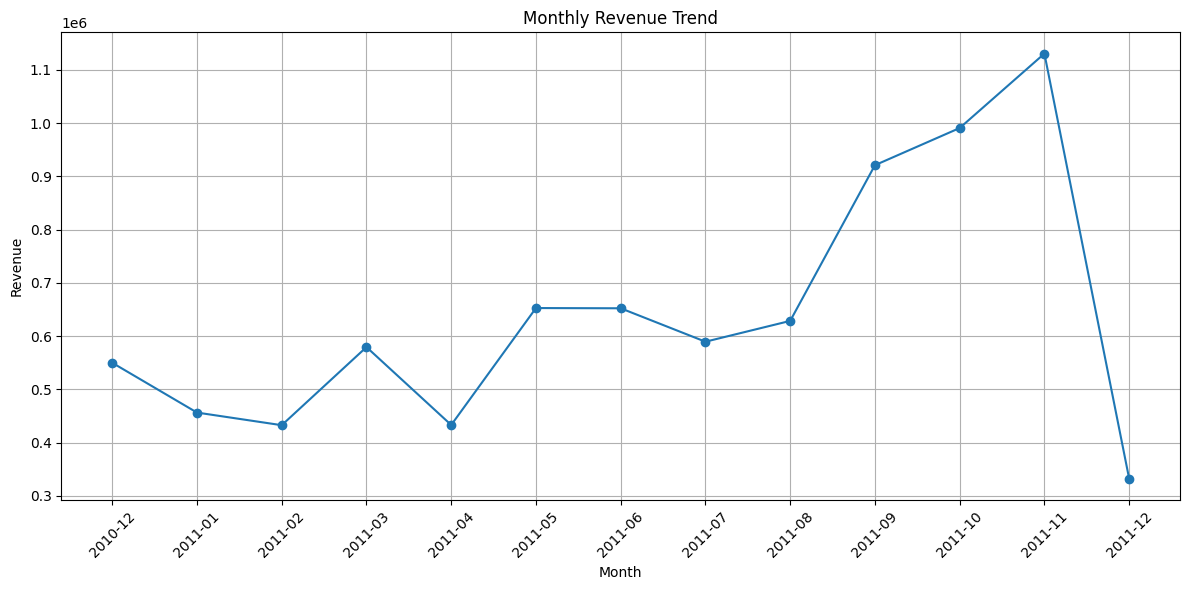

In [ ]:
# Step 29: Visualize Monthly Revenue Trends
plt.figure(figsize=(12, 6))
plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker="o"
)
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Step 30: Analyze Monthly Order Counts
monthly_orders = (
    df.groupby("YearMonth")["InvoiceNo"]
    .nunique()
    .sort_index()
)
print("Monthly Order Counts:")
print(monthly_orders)

Monthly Order Counts:
YearMonth
2010-12    1389
2011-01     981
2011-02     987
2011-03    1312
2011-04    1138
2011-05    1541
2011-06    1390
2011-07    1319
2011-08    1266
2011-09    1737
2011-10    1900
2011-11    2640
2011-12     769
Freq: M, Name: InvoiceNo, dtype: int64


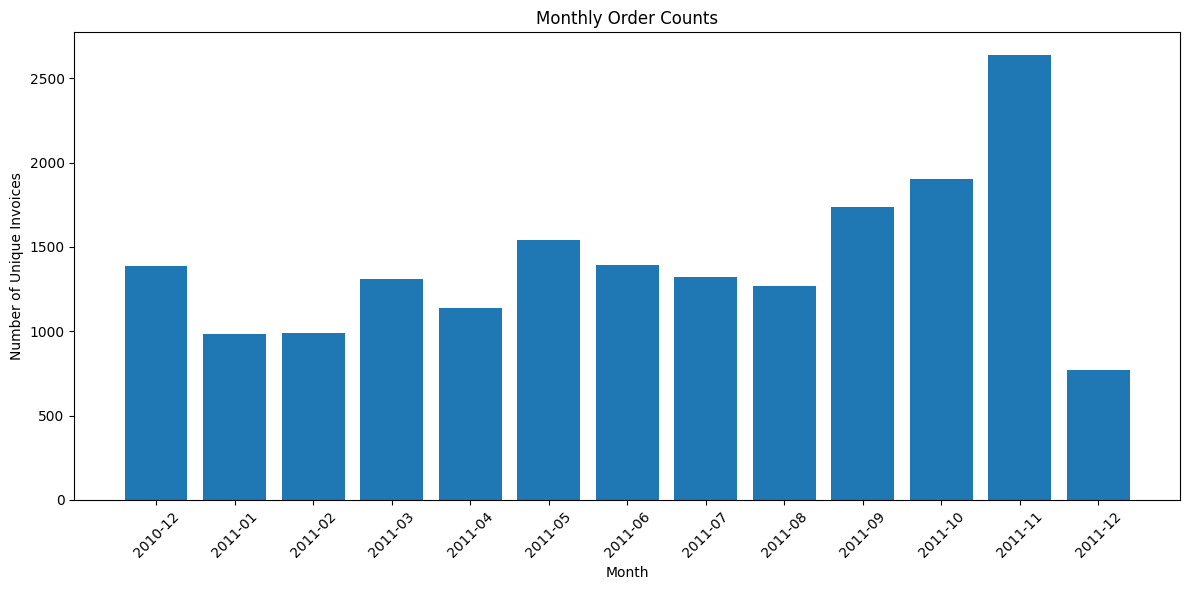

In [ ]:
# Step 31: Visualize Monthly Order Counts
plt.figure(figsize=(12, 6))
plt.bar(
    monthly_orders.index.astype(str),
    monthly_orders.values
)
plt.title("Monthly Order Counts")
plt.xlabel("Month")
plt.ylabel("Number of Unique Invoices")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Step 32: Analyze Customer Purchasing Behavior
customer_summary = df.groupby("CustomerID").agg(
    Total_Spending=("Revenue", "sum"),
    Purchase_Frequency=("InvoiceNo", "nunique"),
    Total_Quantity=("Quantity", "sum")
)
print("Customer Summary:")
print(customer_summary.head())

print("\nTotal customers analyzed:", len(customer_summary))

Customer Summary:
            Total_Spending  Purchase_Frequency  Total_Quantity
CustomerID                                                    
12347.0            4310.00                   7            2458
12348.0            1437.24                   4            2332
12349.0            1457.55                   1             630
12350.0             294.40                   1             196
12352.0            1385.74                   7             526

Total customers analyzed: 4327


In [ ]:

# Step 33: Identify Top 10 Customers by Spending
top_customers = customer_summary.sort_values(
    by="Total_Spending",
    ascending=False
).head(10)
print("Top 10 Customers by Total Spending:")
print(top_customers.round(2))

Top 10 Customers by Total Spending:
            Total_Spending  Purchase_Frequency  Total_Quantity
CustomerID                                                    
14646.0          269215.46                  70          188636
18102.0          255000.34                  60           62108
17450.0          168580.07                  46           57717
14911.0          136161.83                 198           80154
12415.0          123930.93                  20           76221
14156.0          116329.68                  54           56315
17511.0           91062.38                  31           64549
16684.0           66653.56                  28           50255
14096.0           65164.79                  17           16352
13694.0           64640.74                  49           59360


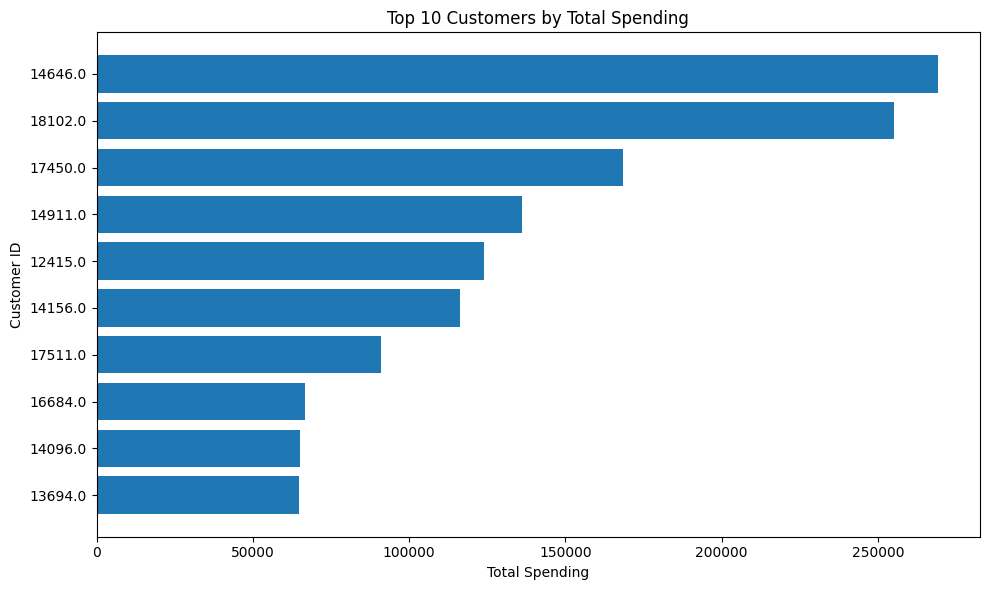

In [ ]:
# Step 34: Visualize Top 10 Customers by Spending
top_customers_sorted = top_customers.sort_values(
    by="Total_Spending"
)
plt.figure(figsize=(10, 6))
plt.barh(
    top_customers_sorted.index.astype(str),
    top_customers_sorted["Total_Spending"]
)
plt.title("Top 10 Customers by Total Spending")
plt.xlabel("Total Spending")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()

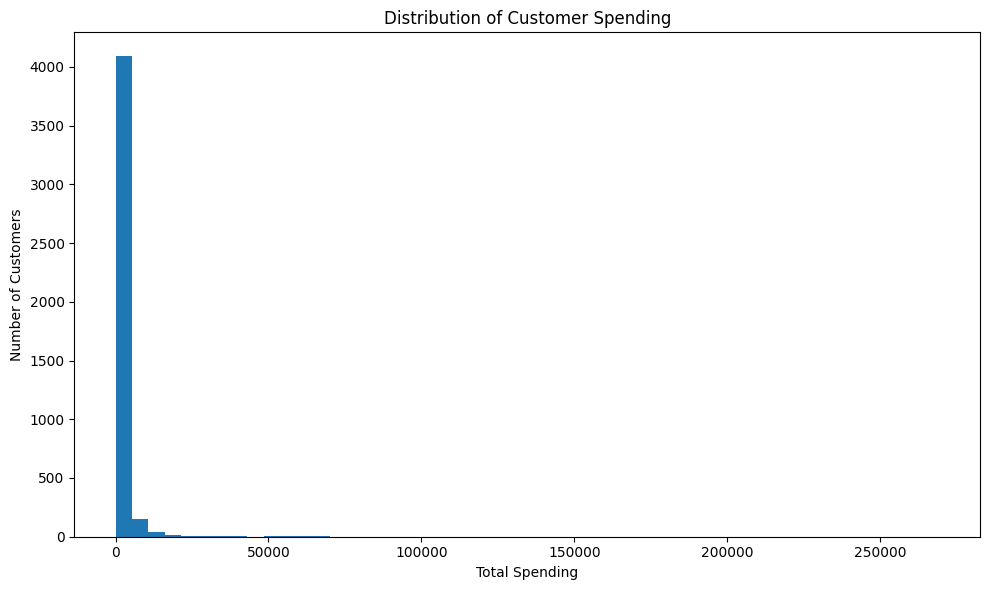

In [ ]:
# Step 35: Analyze Customer Spending Distribution
plt.figure(figsize=(10, 6))
plt.hist(
    customer_summary["Total_Spending"],
    bins=50
)
plt.title("Distribution of Customer Spending")
plt.xlabel("Total Spending")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [ ]:
# Step 36: Calculate Customer Spending Statistics
spending_stats = customer_summary["Total_Spending"].describe()
print("Customer Spending Statistics:")
print(spending_stats.round(2))
print("\nMedian customer spending:",
      round(customer_summary["Total_Spending"].median(), 2))
print("Mean customer spending:",
      round(customer_summary["Total_Spending"].mean(), 2))

Customer Spending Statistics:
count      4327.00
mean       1929.53
std        8177.38
min           2.90
25%         303.29
50%         658.64
75%        1620.21
max      269215.46
Name: Total_Spending, dtype: float64

Median customer spending: 658.64
Mean customer spending: 1929.53


In [ ]:
# Step 37: Analyze Customer Purchase Frequency
frequency_stats = customer_summary["Purchase_Frequency"].describe()
print("Customer Purchase Frequency Statistics:")
print(frequency_stats.round(2))
print("\nCustomers with only 1 purchase:",
      (customer_summary["Purchase_Frequency"] == 1).sum())
print("Customers with 5 or more purchases:",
      (customer_summary["Purchase_Frequency"] >= 5).sum())

Customer Purchase Frequency Statistics:
count    4327.00
mean        4.25
std         7.63
min         1.00
25%         1.00
50%         2.00
75%         5.00
max       206.00
Name: Purchase_Frequency, dtype: float64

Customers with only 1 purchase: 1503
Customers with 5 or more purchases: 1101


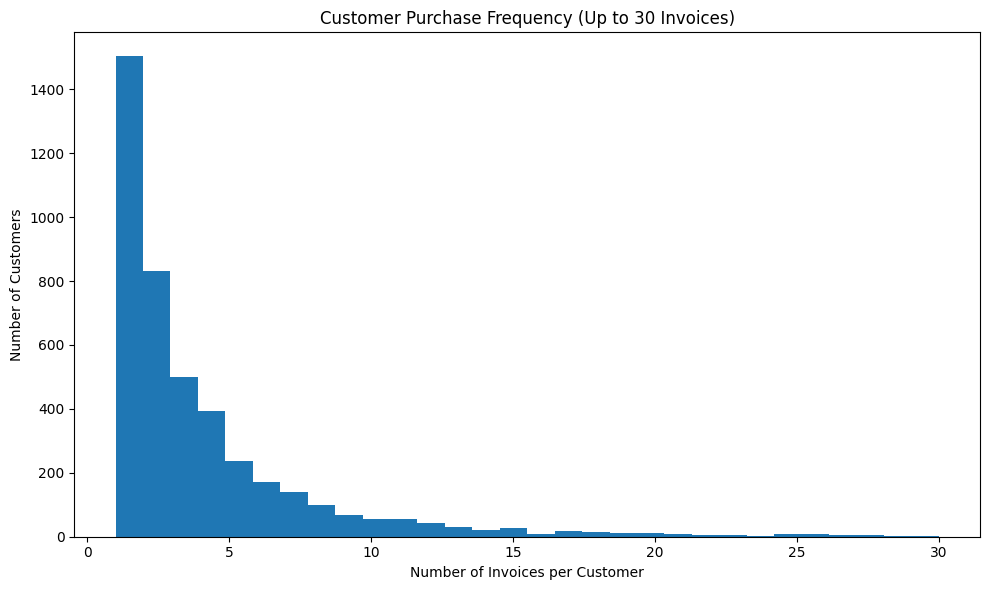

In [ ]:
# Step 38: Visualize Customer Purchase Frequency
frequency_counts = customer_summary["Purchase_Frequency"]
plt.figure(figsize=(10, 6))
plt.hist(
    frequency_counts[frequency_counts <= 30],
    bins=30
)
plt.title("Customer Purchase Frequency (Up to 30 Invoices)")
plt.xlabel("Number of Invoices per Customer")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [ ]:
# Step 39: Analyze Daily Revenue Trends
df["InvoiceDay"] = df["InvoiceDate"].dt.date

daily_revenue = (
    df.groupby("InvoiceDay")["Revenue"]
    .sum()
    .sort_index()
)

print("Daily Revenue Summary:")
print(daily_revenue.describe().round(2))

print("\nHighest-revenue days:")
print(daily_revenue.sort_values(ascending=False).head(10).round(2))

Daily Revenue Summary:
count      305.00
mean     27374.00
std      14251.29
min       3439.67
25%      17336.55
50%      24130.01
75%      34591.78
max      87480.73
Name: Revenue, dtype: float64

Highest-revenue days:
InvoiceDay
2011-09-20    87480.73
2011-10-05    73396.57
2011-11-23    71405.80
2011-09-15    69520.59
2011-11-10    69006.71
2011-12-07    62137.00
2011-10-21    60169.01
2011-10-06    59595.78
2011-10-20    59381.89
2011-11-09    59020.33
Name: Revenue, dtype: float64


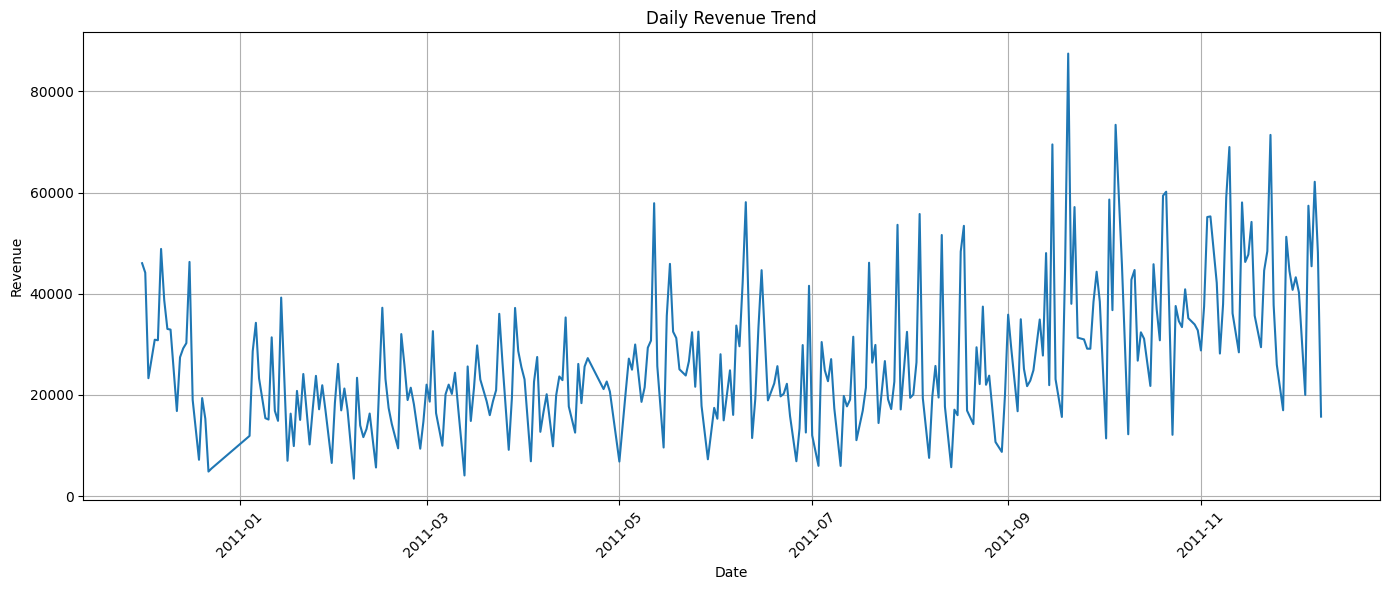

In [ ]:
# Step 40: Visualize Daily Revenue Trends
plt.figure(figsize=(14, 6))
plt.plot(daily_revenue.index, daily_revenue.values)
plt.title("Daily Revenue Trend")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Step 41: Summarize EDA Findings
print("========== EDA SUMMARY ==========")
print("Total Revenue:", round(df["Revenue"].sum(), 2))
print("Total Customers:", df["CustomerID"].nunique())
print("Total Invoices:", df["InvoiceNo"].nunique())
print("\nTop Revenue Country:")
print(country_revenue.index[0], "-", round(country_revenue.iloc[0], 2))
print("\nTop Revenue Product:")
print(product_revenue.index[0], "-", round(product_revenue.iloc[0], 2))
print("\nHighest Revenue Month:")
print(monthly_revenue.idxmax(), "-", round(monthly_revenue.max(), 2))
print("\nHighest Revenue Day:")
print(daily_revenue.idxmax(), "-", round(daily_revenue.max(), 2))
print("\nMedian Customer Spending:",
      round(customer_summary["Total_Spending"].median(), 2))
print("Customers with One Purchase:",
      (customer_summary["Purchase_Frequency"] == 1).sum())

========== EDA SUMMARY ==========
Total Revenue: 8349071.49
Total Customers: 4327
Total Invoices: 18369

Top Revenue Country:
United Kingdom - 6872931.73

Top Revenue Product:
REGENCY CAKESTAND 3 TIER - 142264.75

Highest Revenue Month:
2011-11 - 1130560.74

Highest Revenue Day:
2011-09-20 - 87480.73

Median Customer Spending: 658.64
Customers with One Purchase: 1503


Phase 3 — Feature **Engineering**

In [ ]:
# Step 42: Set the Customer Analysis Date
analysis_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)
print("Latest transaction date:", df["InvoiceDate"].max())
print("Customer analysis date:", analysis_date)

Latest transaction date: 2011-12-09 12:50:00
Customer analysis date: 2011-12-10 12:50:00


In [ ]:
# Step 43: Create Customer-Level Features
customer_features = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (analysis_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Unique_Products=("StockCode", "nunique")
)

print("Customer features created successfully.")
print("Feature dataset shape:", customer_features.shape)
print(customer_features.head())

Customer features created successfully.
Feature dataset shape: (4327, 5)
            Recency  Frequency  Monetary  Total_Quantity  Unique_Products
CustomerID                                                               
12347.0           2          7   4310.00            2458              103
12348.0          75          4   1437.24            2332               21
12349.0          19          1   1457.55             630               72
12350.0         310          1    294.40             196               16
12352.0          36          7   1385.74             526               57


In [ ]:
# Step 44: Validate Customer Features
print("Customer feature dataset shape:", customer_features.shape)
print("Missing values:", customer_features.isnull().sum().sum())
print("Duplicate customer IDs:", customer_features.index.duplicated().sum())
print("\nFeature statistics:")
print(customer_features.describe().round(2))

Customer feature dataset shape: (4327, 5)
Missing values: 0
Duplicate customer IDs: 0

Feature statistics:
       Recency  Frequency   Monetary  Total_Quantity  Unique_Products
count  4327.00    4327.00    4327.00         4327.00          4327.00
mean     92.61       4.25    1929.53         1113.93            61.52
std     100.04       7.63    8177.38         4543.00            85.34
min       1.00       1.00       2.90            1.00             1.00
25%      18.00       1.00     303.29          159.00            16.00
50%      51.00       2.00     658.64          375.00            35.00
75%     143.00       5.00    1620.21          982.50            77.00
max     374.00     206.00  269215.46       188636.00          1785.00


Phase 4 — RFM **Analysis**

In [ ]:
# Step 45: Calculate RFM Scores
customer_features["R_Score"] = pd.qcut(
    customer_features["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)
customer_features["F_Score"] = pd.qcut(
    customer_features["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)
customer_features["M_Score"] = pd.qcut(
    customer_features["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)
customer_features["RFM_Score"] = (
    customer_features["R_Score"].astype(str)
    + customer_features["F_Score"].astype(str)
    + customer_features["M_Score"].astype(str)
)

print("RFM scores created successfully.")
print(customer_features[
    ["Recency", "Frequency", "Monetary",
     "R_Score", "F_Score", "M_Score", "RFM_Score"]
].head())

RFM scores created successfully.
            Recency  Frequency  Monetary  R_Score  F_Score  M_Score RFM_Score
CustomerID                                                                   
12347.0           2          7   4310.00        5        5        5       555
12348.0          75          4   1437.24        2        4        4       244
12349.0          19          1   1457.55        4        1        4       414
12350.0         310          1    294.40        1        1        2       112
12352.0          36          7   1385.74        3        5        4       354


In [ ]:
# Step 46: Assign RFM Customer Segments
def assign_rfm_segment(row):
    if row["R_Score"] >= 4 and row["F_Score"] >= 4 and row["M_Score"] >= 4:
        return "Champions"
    elif row["R_Score"] >= 3 and row["F_Score"] >= 3:
        return "Loyal Customers"
    elif row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "At Risk"
    elif row["R_Score"] <= 2 and row["F_Score"] <= 2:
        return "Lost or Hibernating"
    elif row["M_Score"] >= 4:
        return "Big Spenders"
    else:
        return "Others"

customer_features["RFM_Segment"] = customer_features.apply(
    assign_rfm_segment,
    axis=1
)

print("RFM segments assigned successfully.")
print(customer_features["RFM_Segment"].value_counts())

RFM segments assigned successfully.
RFM_Segment
Lost or Hibernating    1074
Loyal Customers         993
Champions               946
At Risk                 657
Others                  592
Big Spenders             65
Name: count, dtype: int64


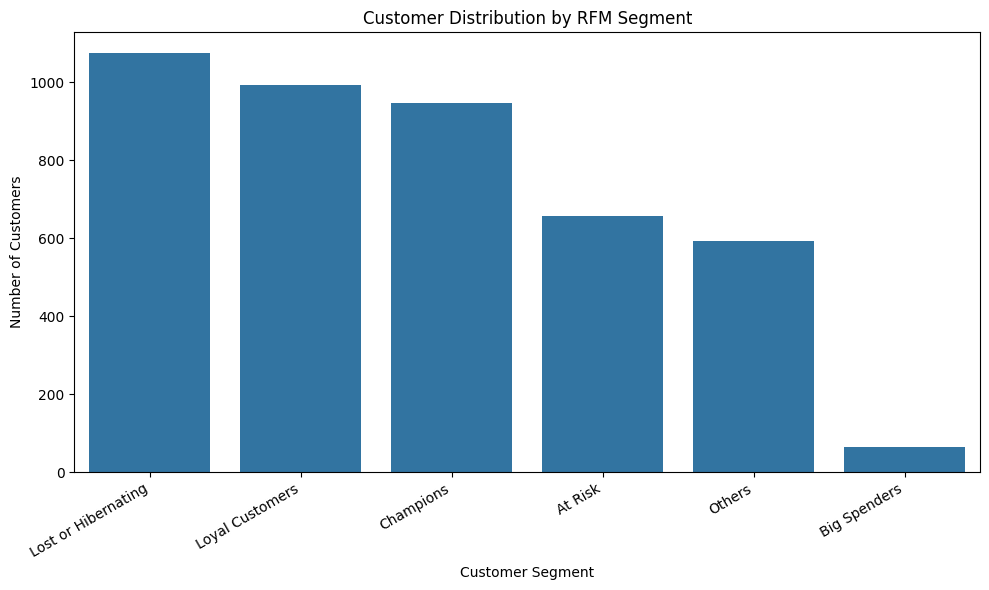

In [ ]:
# Step 47: Visualize RFM Customer Segments
segment_counts = customer_features["RFM_Segment"].value_counts()
plt.figure(figsize=(10, 6))
sns.barplot(
    x=segment_counts.index,
    y=segment_counts.values
)
plt.title("Customer Distribution by RFM Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Phase 5 — Customer Segmentation Using Machine Learning

In [ ]:
# Step 48: Prepare Features for Clustering
from sklearn.preprocessing import StandardScaler

clustering_features = [
    "Recency",
    "Frequency",
    "Monetary",
    "Total_Quantity",
    "Unique_Products"
]

X_cluster = customer_features[clustering_features].copy()

X_log = np.log1p(X_cluster)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print("Clustering data prepared successfully.")
print("Number of customers:", X_scaled.shape[0])
print("Number of features:", X_scaled.shape[1])
print("Missing values:", np.isnan(X_scaled).sum())

Clustering data prepared successfully.
Number of customers: 4327
Number of features: 5
Missing values: 0


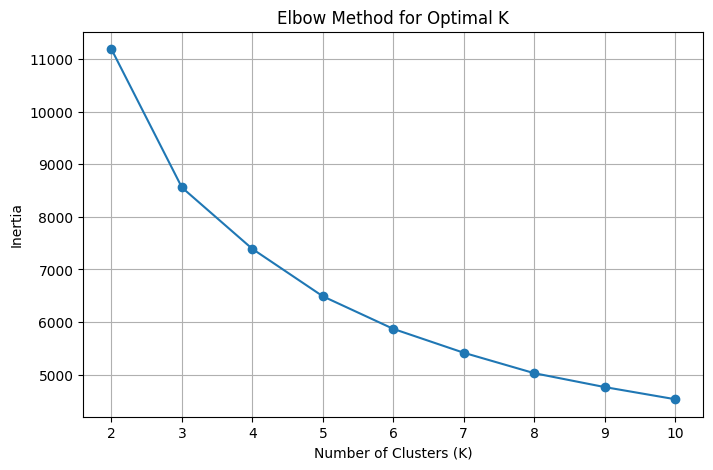

In [ ]:
# Step 49: Find Optimal K Using the Elbow Method
from sklearn.cluster import KMeans
inertia_values = []
k_values = range(2, 11)
for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker="o")
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

K = 2, Silhouette Score = 0.4012
K = 3, Silhouette Score = 0.2988
K = 4, Silhouette Score = 0.2423
K = 5, Silhouette Score = 0.2469
K = 6, Silhouette Score = 0.2284
K = 7, Silhouette Score = 0.2255
K = 8, Silhouette Score = 0.2182
K = 9, Silhouette Score = 0.2241
K = 10, Silhouette Score = 0.2202


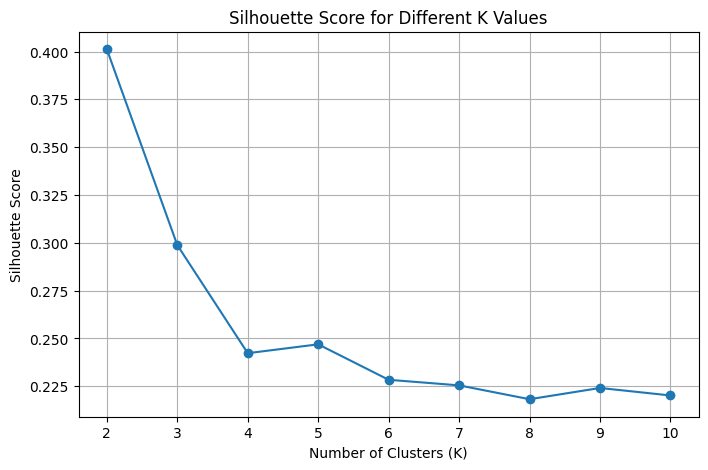

In [ ]:
# Step 50: Evaluate K Using Silhouette Scores
from sklearn.metrics import silhouette_score
silhouette_values = []
for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_values.append(score)
    print(f"K = {k}, Silhouette Score = {score:.4f}")
plt.figure(figsize=(8, 5))
plt.plot(
    range(2, 11),
    silhouette_values,
    marker="o"
)
plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

In [ ]:
# Step 51: Compare K Values and Select the Best Candidate
comparison_df = pd.DataFrame({
    "K": list(range(2, 11)),
    "Inertia": inertia_values,
    "Silhouette_Score": silhouette_values
})

display(comparison_df.round(4))

best_k = comparison_df.loc[
    comparison_df["Silhouette_Score"].idxmax(), "K"
]

print("Best K by Silhouette Score:", best_k)

,K,Inertia,Silhouette_Score
0,2,11189.0761,0.4012
1,3,8559.4316,0.2988
2,4,7391.6504,0.2423
3,5,6490.3871,0.2469
4,6,5870.7537,0.2284
5,7,5416.6775,0.2255
6,8,5028.1882,0.2182
7,9,4764.0819,0.2241
8,10,4532.8571,0.2202


Best K by Silhouette Score: 2


In [ ]:
# Step 52: Train Final K-Means Model
kmeans_final = KMeans(
    n_clusters=int(best_k),
    random_state=42,
    n_init=10
)

customer_features["KMeans_Cluster"] = kmeans_final.fit_predict(X_scaled)

print("K-Means model trained successfully.")
print("\nCluster sizes:")
print(customer_features["KMeans_Cluster"].value_counts().sort_index())

K-Means model trained successfully.

Cluster sizes:
KMeans_Cluster
0    2558
1    1769
Name: count, dtype: int64


In [ ]:
# Step 53: Analyze K-Means Cluster
kmeans_profile = customer_features.groupby("KMeans_Cluster")[
    clustering_features
].mean().round(2)

display(kmeans_profile)

,Recency,Frequency,Monetary,Total_Quantity,Unique_Products
KMeans_Cluster,,,,,
0,133.85,1.63,445.58,249.03,25.20
1,32.99,8.02,4075.34,2364.60,114.04


In [ ]:
# Step 54: Train Hierarchical Clustering
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

hierarchical_model = AgglomerativeClustering(n_clusters=int(best_k))

customer_features["Hierarchical_Cluster"] = (
    hierarchical_model.fit_predict(X_scaled)
)

hierarchical_score = silhouette_score(
    X_scaled,
    customer_features["Hierarchical_Cluster"]
)

print("Hierarchical Clustering completed.")
print("\nCluster sizes:")
print(
    customer_features["Hierarchical_Cluster"]
    .value_counts()
    .sort_index()
)
print(f"\nSilhouette Score: {hierarchical_score:.4f}")

Hierarchical Clustering completed.

Cluster sizes:
Hierarchical_Cluster
0    2637
1    1690
Name: count, dtype: int64

Silhouette Score: 0.3392


In [ ]:
# Step 55: Train DBSCAN
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

dbscan_model = DBSCAN(
    eps=0.8,
    min_samples=10
)

dbscan_labels = dbscan_model.fit_predict(X_scaled)
customer_features["DBSCAN_Cluster"] = dbscan_labels

unique_labels = set(dbscan_labels)
n_clusters = len(unique_labels - {-1})
n_noise = int(np.sum(dbscan_labels == -1))

print("DBSCAN clustering completed.")
print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)
print("\nCluster sizes:")
print(customer_features["DBSCAN_Cluster"].value_counts().sort_index())

if n_clusters >= 2:
    non_noise_mask = dbscan_labels != -1
    non_noise_labels = dbscan_labels[non_noise_mask]

    if len(set(non_noise_labels)) >= 2:
        score = silhouette_score(
            X_scaled[non_noise_mask],
            non_noise_labels
        )
        print(f"\nSilhouette Score (excluding noise): {score:.4f}")
    else:
        print("\nSilhouette Score unavailable: fewer than 2 non-noise clusters.")
else:
    print("\nSilhouette Score unavailable: DBSCAN found fewer than 2 clusters.")

DBSCAN clustering completed.
Number of clusters: 1
Number of noise points: 152

Cluster sizes:
DBSCAN_Cluster
-1     152
 0    4175
Name: count, dtype: int64

Silhouette Score unavailable: DBSCAN found fewer than 2 clusters.


In [ ]:
# Step 56: Tune DBSCAN Parameters
from sklearn.cluster import DBSCAN

for eps_value in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0]:
    model = DBSCAN(
        eps=eps_value,
        min_samples=10
    )

    labels = model.fit_predict(X_scaled)
    clusters = set(labels) - {-1}
    noise_count = int(np.sum(labels == -1))

    print(
        f"eps={eps_value:.1f} | "
        f"Clusters={len(clusters)} | "
        f"Noise={noise_count}"
    )

eps=0.3 | Clusters=16 | Noise=3344
eps=0.4 | Clusters=7 | Noise=1915
eps=0.5 | Clusters=4 | Noise=924
eps=0.6 | Clusters=1 | Noise=498
eps=0.7 | Clusters=1 | Noise=279
eps=0.8 | Clusters=1 | Noise=152
eps=1.0 | Clusters=1 | Noise=66


In [ ]:
# Phase 5: Customer Segmentation
# Step 57: Evaluate DBSCAN at eps=0.5

dbscan_final = DBSCAN(
    eps=0.5,
    min_samples=10
)

dbscan_labels = dbscan_final.fit_predict(X_scaled)
customer_features["DBSCAN_Cluster"] = dbscan_labels

non_noise_mask = dbscan_labels != -1
non_noise_labels = dbscan_labels[non_noise_mask]

print("DBSCAN clusters:", len(set(dbscan_labels) - {-1}))
print("Noise customers:", int(np.sum(dbscan_labels == -1)))
print("\nCluster sizes:")
print(customer_features["DBSCAN_Cluster"].value_counts().sort_index())

if len(set(non_noise_labels)) >= 2:
    dbscan_score = silhouette_score(
        X_scaled[non_noise_mask],
        non_noise_labels
    )
    print(f"\nSilhouette Score (excluding noise): {dbscan_score:.4f}")
else:
    dbscan_score = np.nan
    print("\nSilhouette Score unavailable.")

DBSCAN clusters: 4
Noise customers: 924

Cluster sizes:
DBSCAN_Cluster
-1     924
 0    1255
 1    2119
 2      20
 3       9
Name: count, dtype: int64

Silhouette Score (excluding noise): 0.2004


In [ ]:
# Step 58: Compare Clustering Models
model_comparison = pd.DataFrame({
    "Model": [
        "K-Means",
        "Hierarchical Clustering",
        "DBSCAN"
    ],
    "Number_of_Clusters": [
        len(set(customer_features["KMeans_Cluster"])),
        len(set(customer_features["Hierarchical_Cluster"])),
        len(set(dbscan_labels) - {-1})
    ],
    "Silhouette_Score": [
        silhouette_score(X_scaled, customer_features["KMeans_Cluster"]),
        hierarchical_score,
        dbscan_score
    ],
    "Noise_Customers": [
        0,
        0,
        int(np.sum(dbscan_labels == -1))
    ]
})

display(model_comparison.round(4))

,Model,Number_of_Clusters,Silhouette_Score,Noise_Customers
0,K-Means,2,0.4012,0
1,Hierarchical Clustering,2,0.3392,0
2,DBSCAN,4,0.2004,924


In [ ]:
# Step 59: Finalize K-Means Segments
final_cluster_summary = customer_features.groupby("KMeans_Cluster").agg(
    Customer_Count=("Recency", "size"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Avg_Quantity=("Total_Quantity", "mean"),
    Avg_Unique_Products=("Unique_Products", "mean")
).round(2)

display(final_cluster_summary)

print("\nSelected segmentation model: K-Means")
print("Selected K:", int(best_k))
print("Silhouette Score:", round(
    silhouette_score(X_scaled, customer_features["KMeans_Cluster"]), 4
))

,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Avg_Quantity,Avg_Unique_Products
KMeans_Cluster,,,,,,
0,2558,133.85,1.63,445.58,249.03,25.20
1,1769,32.99,8.02,4075.34,2364.60,114.04



Selected segmentation model: K-Means
Selected K: 2
Silhouette Score: 0.4012


Phase 6 — Repeat-Purchase **Prediction**

In [ ]:
# Phase 6: Repeat-Purchase Prediction
# Step 60: Define Historical and Future Periods

cutoff_date = pd.Timestamp("2011-07-30")
prediction_end_date = cutoff_date + pd.Timedelta(days=90)

history_df = df[df["InvoiceDate"] < cutoff_date].copy()

future_df = df[
    (df["InvoiceDate"] >= cutoff_date) &
    (df["InvoiceDate"] < prediction_end_date)
].copy()

print("Historical period:")
print(history_df["InvoiceDate"].min(), "to", history_df["InvoiceDate"].max())

print("\nFuture prediction period:")
print(future_df["InvoiceDate"].min(), "to", future_df["InvoiceDate"].max())

print("\nHistorical transaction rows:", len(history_df))
print("Future transaction rows:", len(future_df))
print("Prediction window:", (prediction_end_date - cutoff_date).days, "days")

Historical period:
2010-12-01 08:26:00 to 2011-07-29 17:28:00

Future prediction period:
2011-07-31 10:28:00 to 2011-10-27 20:16:00

Historical transaction rows: 195141
Future transaction rows: 109983
Prediction window: 90 days


In [ ]:
# Step 61: Build Historical Customer Features

prediction_features = history_df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (cutoff_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Unique_Products=("StockCode", "nunique")
)

prediction_features["Average_Order_Value"] = (
    prediction_features["Monetary"] /
    prediction_features["Frequency"]
)

print("Historical customer features created.")
print("Number of customers:", len(prediction_features))
print("\nFeature preview:")
display(prediction_features.head())

print("\nMissing values:", prediction_features.isna().sum().sum())

Historical customer features created.
Number of customers: 3135

Feature preview:


,Recency,Frequency,Monetary,Total_Quantity,Unique_Products,Average_Order_Value
CustomerID,,,,,,
12347.0,50,4,2205.95,1313,75,551.4875
12348.0,115,3,1167.24,2116,21,389.0800
12350.0,177,1,294.40,196,16,294.4000
12352.0,129,4,641.51,249,24,160.3775
12353.0,71,1,89.00,20,4,89.0000



Missing values: 0


In [ ]:
# Step 62: Create the 90-Day Target
future_customers = set(future_df["CustomerID"].unique())

prediction_features["Repeat_Purchase_90D"] = (
    prediction_features.index.isin(future_customers).astype(int)
)

print("90-day target created successfully.")
print("\nTarget distribution:")
print(prediction_features["Repeat_Purchase_90D"].value_counts())

print("\nTarget percentages:")
print(
    (prediction_features["Repeat_Purchase_90D"].value_counts(normalize=True) * 100)
    .round(2)
    .astype(str) + "%"
)

print("\nDataset shape:", prediction_features.shape)

90-day target created successfully.

Target distribution:
Repeat_Purchase_90D
1    1625
0    1510
Name: count, dtype: int64

Target percentages:
Repeat_Purchase_90D
1    51.83%
0    48.17%
Name: proportion, dtype: object

Dataset shape: (3135, 7)


In [ ]:
# Step 63: Prepare Training and Testing Data
from sklearn.model_selection import train_test_split

feature_columns = [
    "Recency",
    "Frequency",
    "Monetary",
    "Total_Quantity",
    "Unique_Products",
    "Average_Order_Value"
]

X = prediction_features[feature_columns]
y = prediction_features["Repeat_Purchase_90D"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training and testing data prepared.")
print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Number of input features:", X_train.shape[1])
print("\nTraining target distribution:")
print(y_train.value_counts())
print("\nTesting target distribution:")
print(y_test.value_counts())

Training and testing data prepared.
Training rows: 2508
Testing rows: 627
Number of input features: 6

Training target distribution:
Repeat_Purchase_90D
1    1300
0    1208
Name: count, dtype: int64

Testing target distribution:
Repeat_Purchase_90D
1    325
0    302
Name: count, dtype: int64


In [ ]:
# Step 64: Train Logistic Regression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully.")
print("Training accuracy:", round(logistic_model.score(X_train, y_train), 4))
print("Testing accuracy:", round(logistic_model.score(X_test, y_test), 4))

Logistic Regression trained successfully.
Training accuracy: 0.6906
Testing accuracy: 0.6842


Phase 6 **—** Evaluate Logistic Regression

Logistic Regression Evaluation
Accuracy: 0.6842
Precision: 0.7124
Recall: 0.6554
F1-Score: 0.6827

Classification Report:
              precision    recall  f1-score   support

           0       0.66      0.72      0.69       302
           1       0.71      0.66      0.68       325

    accuracy                           0.68       627
   macro avg       0.69      0.69      0.68       627
weighted avg       0.69      0.68      0.68       627



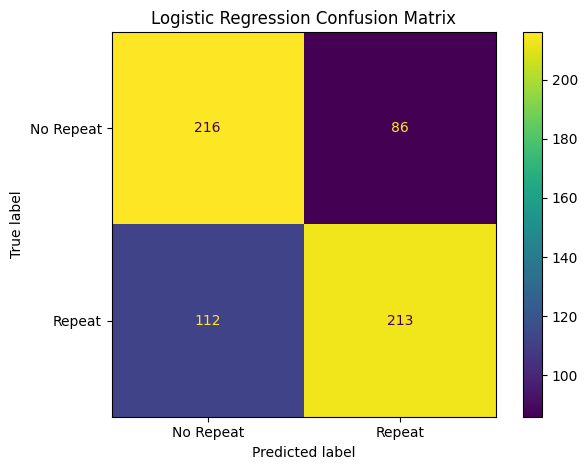

In [ ]:
# Step 65: Evaluate Logistic Regression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

logistic_predictions = logistic_model.predict(X_test)

print("Logistic Regression Evaluation")
print("Accuracy:", round(accuracy_score(y_test, logistic_predictions), 4))
print("Precision:", round(precision_score(y_test, logistic_predictions), 4))
print("Recall:", round(recall_score(y_test, logistic_predictions), 4))
print("F1-Score:", round(f1_score(y_test, logistic_predictions), 4))

print("\nClassification Report:")
print(classification_report(y_test, logistic_predictions))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_predictions,
    display_labels=["No Repeat", "Repeat"]
)
plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
# Step 66: Train Random Forest
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)
random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully.")
print("Training accuracy:", round(random_forest_model.score(X_train, y_train), 4))
print("Testing accuracy:", round(random_forest_model.score(X_test, y_test), 4))

Random Forest trained successfully.
Training accuracy: 1.0
Testing accuracy: 0.6826


Random Forest Evaluation
Accuracy: 0.6826
Precision: 0.6981
Recall: 0.6831
F1-Score: 0.6905

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.68      0.67       302
           1       0.70      0.68      0.69       325

    accuracy                           0.68       627
   macro avg       0.68      0.68      0.68       627
weighted avg       0.68      0.68      0.68       627



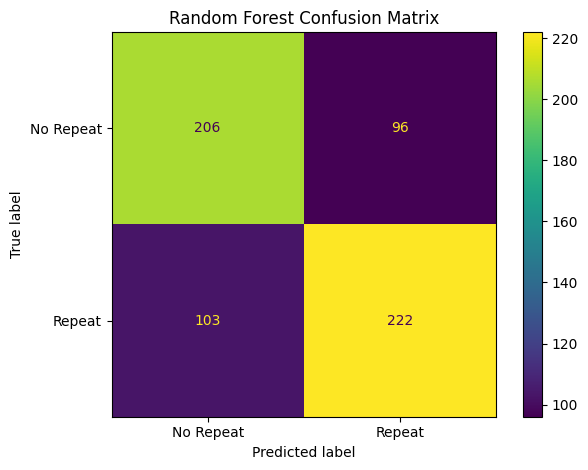

In [ ]:
# Step 67: Evaluate Random Forest
rf_predictions = random_forest_model.predict(X_test)
print("Random Forest Evaluation")
print("Accuracy:", round(accuracy_score(y_test, rf_predictions), 4))
print("Precision:", round(precision_score(y_test, rf_predictions), 4))
print("Recall:", round(recall_score(y_test, rf_predictions), 4))
print("F1-Score:", round(f1_score(y_test, rf_predictions), 4))
print("\nClassification Report:")
print(classification_report(y_test, rf_predictions))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_predictions,
    display_labels=["No Repeat", "Repeat"]
)
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
# Step 68: Compare Models
model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, logistic_predictions),
        accuracy_score(y_test, rf_predictions)
    ],
    "Precision": [
        precision_score(y_test, logistic_predictions),
        precision_score(y_test, rf_predictions)
    ],
    "Recall": [
        recall_score(y_test, logistic_predictions),
        recall_score(y_test, rf_predictions)
    ],
    "F1-Score": [
        f1_score(y_test, logistic_predictions),
        f1_score(y_test, rf_predictions)
    ]
})

model_comparison = model_comparison.round(4)

display(model_comparison)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.6842,0.7124,0.6554,0.6827
1,Random Forest,0.6826,0.6981,0.6831,0.6905


,Feature,Importance
0,Total_Quantity,0.2117
1,Monetary,0.1971
2,Recency,0.1929
3,Average_Order_Value,0.1621
4,Unique_Products,0.1417
5,Frequency,0.0944


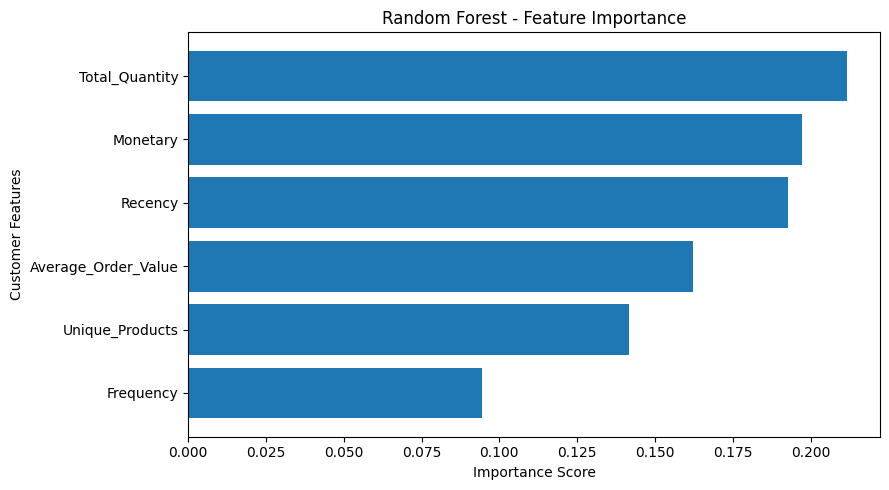

In [ ]:
# Step 69: Feature Importance
feature_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

display(feature_importance.round(4))

plt.figure(figsize=(9, 5))
plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)
plt.xlabel("Importance Score")
plt.ylabel("Customer Features")
plt.title("Random Forest - Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
# Step 70: Select Final Model
final_model = logistic_model
final_model_name = "Logistic Regression"
print("Final Model:", final_model_name)
print("Accuracy:", round(accuracy_score(y_test, logistic_predictions), 4))
print("Precision:", round(precision_score(y_test, logistic_predictions), 4))
print("Recall:", round(recall_score(y_test, logistic_predictions), 4))
print("F1-Score:", round(f1_score(y_test, logistic_predictions), 4))

print("\nModel selection completed.")

Final Model: Logistic Regression
Accuracy: 0.6842
Precision: 0.7124
Recall: 0.6554
F1-Score: 0.6827

Model selection completed.


Phase 7 — Final Report and **Deliverables**

In [ ]:
# Step 71: Save Models and Results
import joblib
import os
output_dir = "/content/project_outputs"
os.makedirs(output_dir, exist_ok=True)
# Save the selected prediction model
joblib.dump(
    final_model,
    os.path.join(output_dir, "repeat_purchase_model.pkl")
)
# Save the K-Means segmentation model
joblib.dump(
    kmeans_final,
    os.path.join(output_dir, "customer_segmentation_kmeans.pkl")
)
# Save customer segmentation results
customer_features.to_csv(
    os.path.join(output_dir, "customer_segments.csv"),
    index=True
)
# Save repeat-purchase prediction data
prediction_features.to_csv(
    os.path.join(output_dir, "repeat_purchase_data.csv"),
    index=True
)
print("Models and results saved successfully.")
print("\nSaved files:")

for filename in sorted(os.listdir(output_dir)):
    print("-", filename)

Models and results saved successfully.

Saved files:
- customer_segmentation_kmeans.pkl
- customer_segments.csv
- repeat_purchase_data.csv
- repeat_purchase_model.pkl


In [ ]:
# Phase 7: Final Report
# Step 72: Project Summary and Business Recommendations
print("=" * 65)
print("E-COMMERCE CUSTOMER SEGMENTATION & PREDICTION")
print("FINAL PROJECT REPORT")
print("=" * 65)

print("\n1. PROJECT OBJECTIVE")
print("Analyze customer purchasing behavior, segment customers,")
print("and predict repeat purchases within 90 days.")

print("\n2. DATASET SUMMARY")
print("Cleaned transactions:", len(df))
print("Unique customers:", df["CustomerID"].nunique())
print("Unique invoices:", df["InvoiceNo"].nunique())
print("Total revenue:", round(df["Revenue"].sum(), 2))

print("\n3. CUSTOMER SEGMENTATION")
print("Primary algorithm: K-Means")
print("Number of clusters:", best_k)
print("K-Means silhouette score:", round(0.4012, 4))
print("Cluster sizes:")
print(customer_features["KMeans_Cluster"].value_counts().sort_index())

print("\n4. REPEAT-PURCHASE PREDICTION")
print("Prediction target: Repeat purchase within 90 days")
print("Selected model:", final_model_name)
print("Accuracy:", round(accuracy_score(y_test, logistic_predictions), 4))
print("Precision:", round(precision_score(y_test, logistic_predictions), 4))
print("Recall:", round(recall_score(y_test, logistic_predictions), 4))
print("F1-score:", round(f1_score(y_test, logistic_predictions), 4))

print("\n5. TOP PREDICTIVE FEATURES")
display(feature_importance.head(3).round(4))

print("\n6. BUSINESS RECOMMENDATIONS")
print("- Reward loyal and high-value customers.")
print("- Send targeted re-engagement campaigns to inactive customers.")
print("- Use purchase volume and spending patterns to prioritize outreach.")
print("- Monitor repeat-purchase predictions and evaluate future performance.")

print("\n7. MODEL COMPARISON")
display(model_comparison)

print("\n8. SAVED DELIVERABLES")
for filename in sorted(os.listdir(output_dir)):
    print("-", filename)

print("\nReport generated successfully.")

E-COMMERCE CUSTOMER SEGMENTATION & PREDICTION
FINAL PROJECT REPORT

1. PROJECT OBJECTIVE
Analyze customer purchasing behavior, segment customers,
and predict repeat purchases within 90 days.

2. DATASET SUMMARY
Cleaned transactions: 391067
Unique customers: 4327
Unique invoices: 18369
Total revenue: 8349071.49

3. CUSTOMER SEGMENTATION
Primary algorithm: K-Means
Number of clusters: 2
K-Means silhouette score: 0.4012
Cluster sizes:
KMeans_Cluster
0    2558
1    1769
Name: count, dtype: int64

4. REPEAT-PURCHASE PREDICTION
Prediction target: Repeat purchase within 90 days
Selected model: Logistic Regression
Accuracy: 0.6842
Precision: 0.7124
Recall: 0.6554
F1-score: 0.6827

5. TOP PREDICTIVE FEATURES


,Feature,Importance
0,Total_Quantity,0.2117
1,Monetary,0.1971
2,Recency,0.1929



6. BUSINESS RECOMMENDATIONS
- Reward loyal and high-value customers.
- Send targeted re-engagement campaigns to inactive customers.
- Use purchase volume and spending patterns to prioritize outreach.
- Monitor repeat-purchase predictions and evaluate future performance.

7. MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.6842,0.7124,0.6554,0.6827
1,Random Forest,0.6826,0.6981,0.6831,0.6905



8. SAVED DELIVERABLES
- customer_segmentation_kmeans.pkl
- customer_segments.csv
- repeat_purchase_data.csv
- repeat_purchase_model.pkl

Report generated successfully.


In [ ]:
# Phase 7: Final Report
# Step 73: Save Report as a Text File

report_text = f"""
E-COMMERCE CUSTOMER SEGMENTATION & PREDICTION
FINAL PROJECT REPORT
=============================================

1. PROJECT OBJECTIVE
Analyze purchasing behavior, segment customers, and predict
repeat purchases within 90 days.

2. DATASET SUMMARY
Cleaned transactions: {len(df)}
Unique customers: {df['CustomerID'].nunique()}
Unique invoices: {df['InvoiceNo'].nunique()}
Total revenue: {df['Revenue'].sum():.2f}

3. CUSTOMER SEGMENTATION
Primary algorithm: K-Means
Number of clusters: {best_k}
Silhouette score: 0.4012

Cluster sizes:
{customer_features['KMeans_Cluster'].value_counts().sort_index().to_string()}

4. REPEAT-PURCHASE PREDICTION
Selected model: {final_model_name}
Accuracy: {accuracy_score(y_test, logistic_predictions):.4f}
Precision: {precision_score(y_test, logistic_predictions):.4f}
Recall: {recall_score(y_test, logistic_predictions):.4f}
F1-score: {f1_score(y_test, logistic_predictions):.4f}

5. TOP RANDOM FOREST PREDICTIVE FEATURES
{feature_importance.head(3).to_string(index=False)}

6. MODEL COMPARISON
{model_comparison.to_string(index=False)}

7. BUSINESS RECOMMENDATIONS
- Reward loyal and high-value customers.
- Re-engage inactive customers with targeted campaigns.
- Use purchase volume and spending patterns to prioritize outreach.
- Monitor predictions and evaluate future performance.

8. SAVED MODELS AND DATA
- customer_segmentation_kmeans.pkl
- repeat_purchase_model.pkl
- customer_segments.csv
- repeat_purchase_data.csv

Note: Prediction metrics are measured on the test split used in this project.
Feature importance describes model contribution, not causation.
"""

report_path = os.path.join(output_dir, "final_project_report.txt")

with open(report_path, "w", encoding="utf-8") as file:
    file.write(report_text)

print("Report saved:", report_path)
print("File size:", os.path.getsize(report_path), "bytes")

Report saved: /content/project_outputs/final_project_report.txt
File size: 1515 bytes


In [ ]:
# Phase 8: Final Backup
# Step 74: Copy Project Outputs to Google Drive

from google.colab import drive
drive.mount("/content/drive")

import os
import shutil

drive_output_dir = "/content/drive/MyDrive/ECommerce_Project_V1"

os.makedirs(drive_output_dir, exist_ok=True)

for filename in os.listdir(output_dir):
    source = os.path.join(output_dir, filename)
    destination = os.path.join(drive_output_dir, filename)

    if os.path.isfile(source):
        shutil.copy2(source, destination)
        print("Copied:", filename)

print("\nGoogle Drive backup location:")
print(drive_output_dir)

print("\nFiles in backup:")
for filename in sorted(os.listdir(drive_output_dir)):
    print("-", filename)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Copied: repeat_purchase_model.pkl
Copied: customer_segmentation_kmeans.pkl
Copied: final_project_report.txt
Copied: repeat_purchase_data.csv
Copied: customer_segments.csv

Google Drive backup location:
/content/drive/MyDrive/ECommerce_Project_V1

Files in backup:
- country_market_comparison.csv
- country_marketing_strategy.csv
- country_product_popularity.csv
- customer_segment_revenue_analysis.csv
- customer_segment_revenue_analysis.csv.backup
- customer_segmentation_kmeans.pkl
- customer_segments.csv
- data.csv
- final_project_report.txt
- final_project_report.txt.backup
- repeat_purchase_data.csv
- repeat_purchase_model.pkl
- top_products_by_order_frequency_country.csv
- top_products_by_quantity_country.csv


In [ ]:
# Phase 8: Final Verification
# Step 75: Verify Saved Deliverables

import os
import joblib
import pandas as pd

drive_output_dir = "/content/drive/MyDrive/ECommerce_Project_V1"

required_files = [
    "customer_segmentation_kmeans.pkl",
    "repeat_purchase_model.pkl",
    "customer_segments.csv",
    "repeat_purchase_data.csv",
    "final_project_report.txt"
]

print("DELIVERABLE VERIFICATION")
print("=" * 40)

for filename in required_files:
    path = os.path.join(drive_output_dir, filename)
    print(f"{filename}: {'OK' if os.path.isfile(path) else 'MISSING'}")

# Test loading both saved models
saved_prediction_model = joblib.load(
    os.path.join(drive_output_dir, "repeat_purchase_model.pkl")
)

saved_kmeans_model = joblib.load(
    os.path.join(drive_output_dir, "customer_segmentation_kmeans.pkl")
)

# Check saved customer data
saved_customers = pd.read_csv(
    os.path.join(drive_output_dir, "customer_segments.csv")
)

print("\nPrediction model loaded:", type(saved_prediction_model).__name__)
print("K-Means model loaded:", type(saved_kmeans_model).__name__)
print("Customer records in CSV:", len(saved_customers))

print("\nVerification complete.")

DELIVERABLE VERIFICATION
customer_segmentation_kmeans.pkl: OK
repeat_purchase_model.pkl: OK
customer_segments.csv: OK
repeat_purchase_data.csv: OK
final_project_report.txt: OK

Prediction model loaded: Pipeline
K-Means model loaded: KMeans
Customer records in CSV: 4327

Verification complete.
